# Regional sea-level projection maps with tide gauges

Combines the two regional sea-level projection notebooks on the same maps:

* **background** — gridded AR6 projections **without vertical land motion** (absolute sea level, as in [the regional maps](regional_indicators.ipynb));
* **circles** — AR6 projections **with vertical land motion** (relative sea level) at every UHSLC tide gauge in the Pacific EEZs, as in [the station projections](station_projections.ipynb).

Both share one colour scale, so a circle that stands out from the surrounding background shows where land motion (subsidence or uplift) makes the local, relative rise differ from the ocean rise. The two quantities are **different**: the circles are not samples of the background field.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level_station_projections.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level_station_projections.py).')
sys.path.insert(0, str(repo_root / 'functions'))

from sea_level_projections import (
    colour_limits, domain_mean, linear_trend, load_ar6_pacific, plot_projection_grid, ssp_label,
)
from sea_level_station_projections import SSP_SCENARIOS, load_ar6_locations, match_stations, pacific_eez_stations
from sst import PacificSST

## 1. Configuration

In [3]:
data_dir = repo_root / 'data'
raw_dir = data_dir / 'projections' / 'sea_level'
grid_cache = data_dir / 'projections' / 'regional' / 'sl_ar6_novlm_medium_pacific.nc'        # no VLM (grid)
locations_cache = data_dir / 'projections' / 'regional' / 'sl_ar6_vlm_medium_locations.nc'   # with VLM (gauges)
eez_file = data_dir / 'regional' / 'Pacific_EEZs' / 'Pacific_EEZs.shp'
fig_dir = repo_root / 'outputs' / 'figures' / 'regional_pacific'
tab_dir = repo_root / 'outputs' / 'tables' / 'regional_pacific'
for directory in (fig_dir, tab_dir):
    directory.mkdir(parents=True, exist_ok=True)

pacific_extent = (125, 245, -35, 35)
ssp_scenarios = list(SSP_SCENARIOS)
horizons = [2050, 2100]
trend_period = (2020, 2100)
from sea_level_projections import TREND_CMAP, CHANGE_CMAP, trend_scale, change_scale  # colour scales of the historical maps
max_match_km = 30
force_download = False

## 2. Gridded projections and tide-gauge projections

The grid is the cached Pacific subset of `ar6-regional_novlm-confidence`; the stations are the UHSLC gauges inside, or within 0.5° of, a Pacific EEZ, each matched to the nearest AR6 tide-gauge location (or grid cell when none is within 30 km) of `ar6-regional-confidence`. Missing files are downloaded.

In [4]:
sl = load_ar6_pacific(raw_dir, grid_cache, ssp_scenarios, pacific_extent, vlm=False, force_download=force_download)
change = sl['change']
eez = gpd.read_file(eez_file).to_crs(4326)
pacific = PacificSST(data_raw=sl, data=sl, eez=eez, extent=pacific_extent)

locs = load_ar6_locations(raw_dir, locations_cache, ssp_scenarios, force_download=force_download)
stations = match_stations(locs, pacific_eez_stations(eez, pacific_extent), max_km=max_match_km)
stations = stations.dropna(subset=['ar6_location']).reset_index(drop=True)
station_change = locs['change'].sel(location=xr.DataArray(stations['ar6_location'].astype(int).values, dims='station'))
print(f"{int(sl.ocean.sum())} ocean grid cells; {len(stations)} UHSLC stations "
      f"({int((stations['ar6_kind'] == 'tide gauge').sum())} matched to an AR6 tide gauge).")

7944 ocean grid cells; 69 UHSLC stations (48 matched to an AR6 tide gauge).


## 3. Absolute (grid) and relative (gauges) sea-level change

Median change relative to 1995–2014. One figure per horizon with the four scenarios; the colour scale is that of the historical change map (blue–red, centred on 0, at least ±25 cm), widened to cover the grid and station values together, so both can be read on the same bar; the trend map uses the historical trend scale (from 0, at least 0–8 mm/yr). Each panel gives the area-weighted mean of the grid (absolute) and the median of the tide gauges (relative).

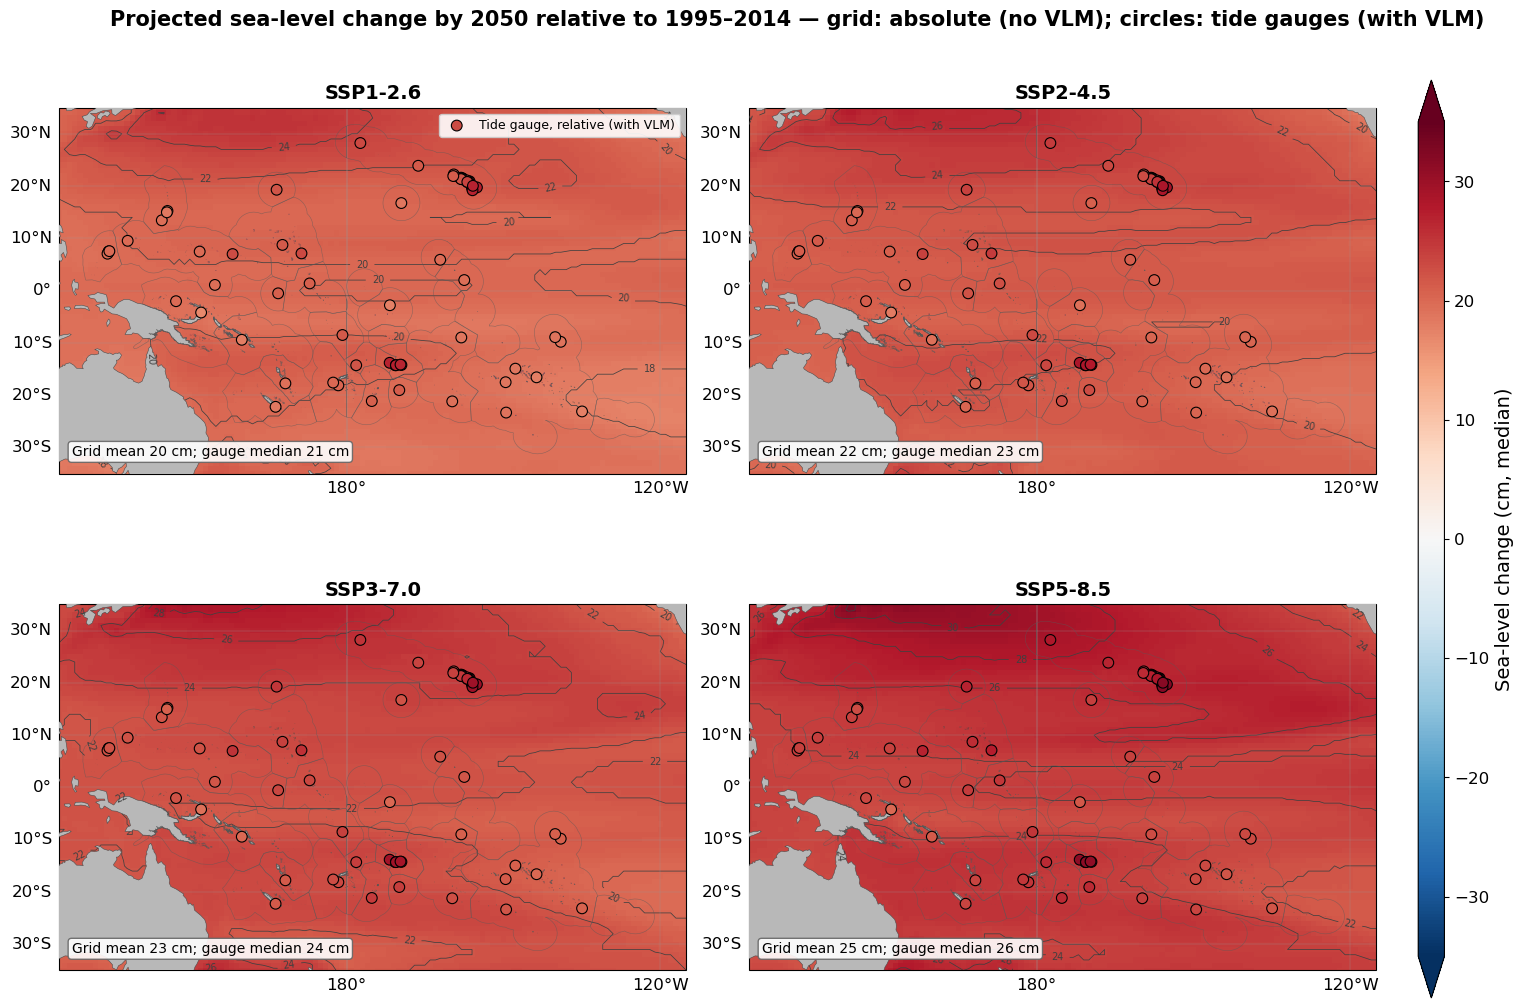

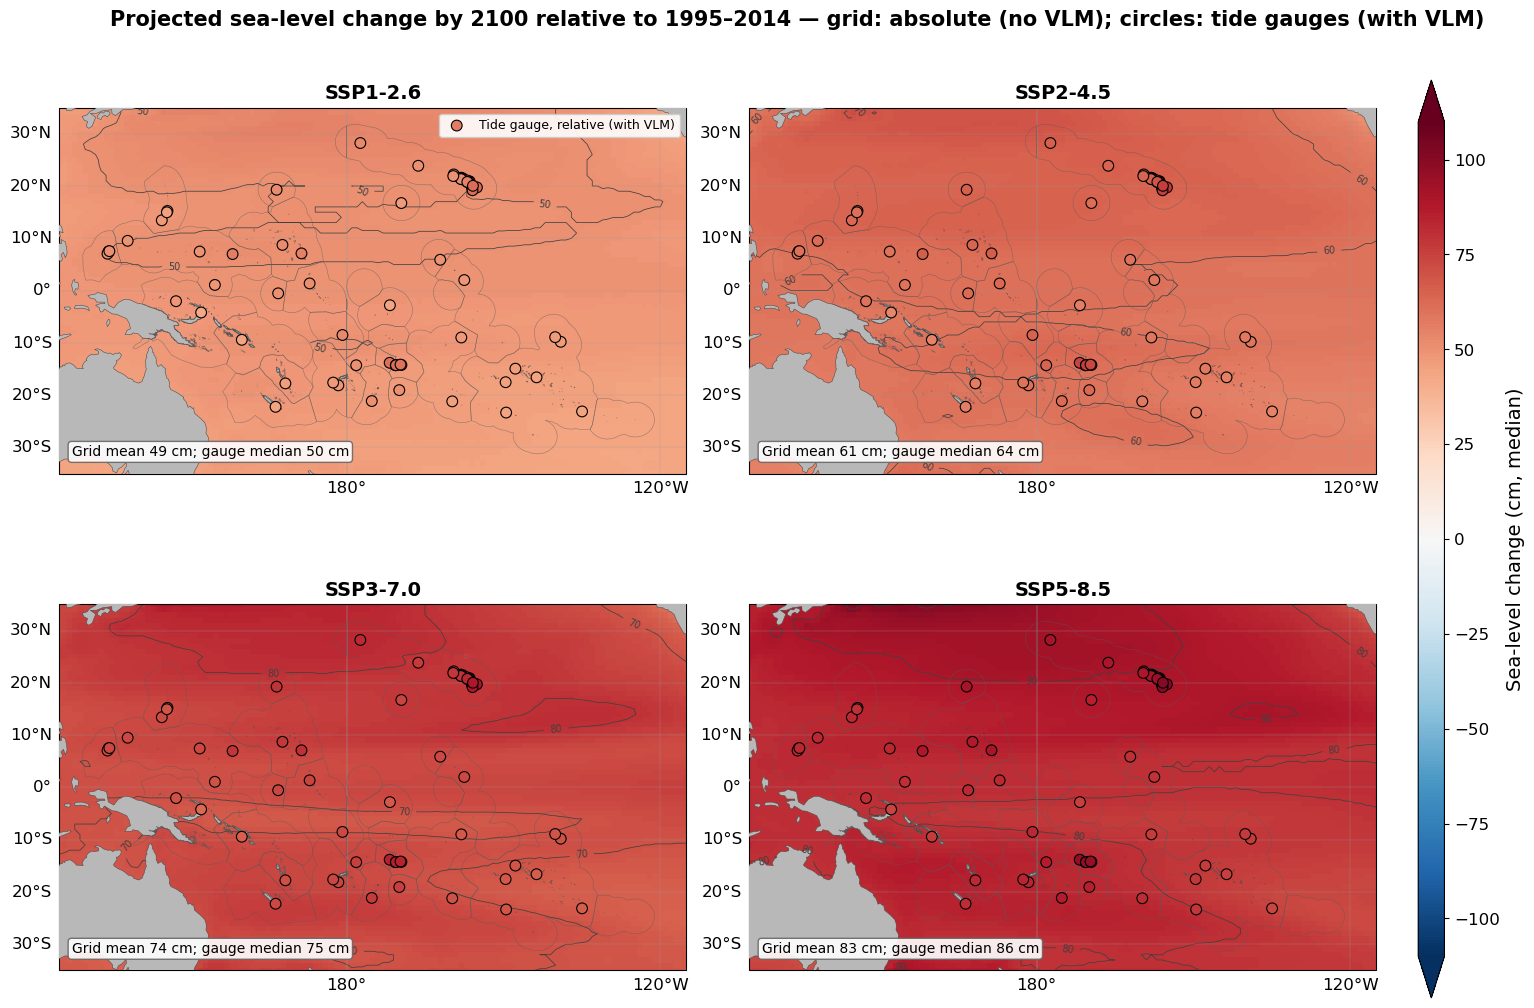

In [5]:
change_mean = domain_mean(change.sel(quantile=0.5))
for year in horizons:
    grid = change.sel(quantile=0.5, year=year)
    gauges = station_change.sel(scenario=ssp_scenarios, quantile=0.5, year=year)
    step = 2 if year <= 2060 else 10
    lo, hi = change_scale(grid, gauges, step=5 if year <= 2060 else 10)
    fig = plot_projection_grid(
        {ssp_label(s): grid.sel(scenario=s) for s in ssp_scenarios}, pacific,
        f'Projected sea-level change by {year} relative to 1995–2014 — grid: absolute (no VLM); circles: tide gauges (with VLM)',
        'Sea-level change (cm, median)', cmap=CHANGE_CMAP, vmin=lo, vmax=hi, contour_levels=colour_limits(grid, step)[2],
        gauges=stations, gauge_values={ssp_label(s): gauges.sel(scenario=s).values for s in ssp_scenarios},
        annotations={ssp_label(s): f"Grid mean {float(change_mean.sel(scenario=s, year=year)):.0f} cm; "
                                   f"gauge median {np.nanmedian(gauges.sel(scenario=s).values):.0f} cm" for s in ssp_scenarios},
        filename=fig_dir / f'PRJ_SL_change_{year}_grid_and_stations_pacific.png',
    )
    plt.show()

## 4. Mean trend 2020–2100

Least-squares slope of the decadal median change between 2020 and 2100 (mm/yr), for the grid and for each tide gauge.

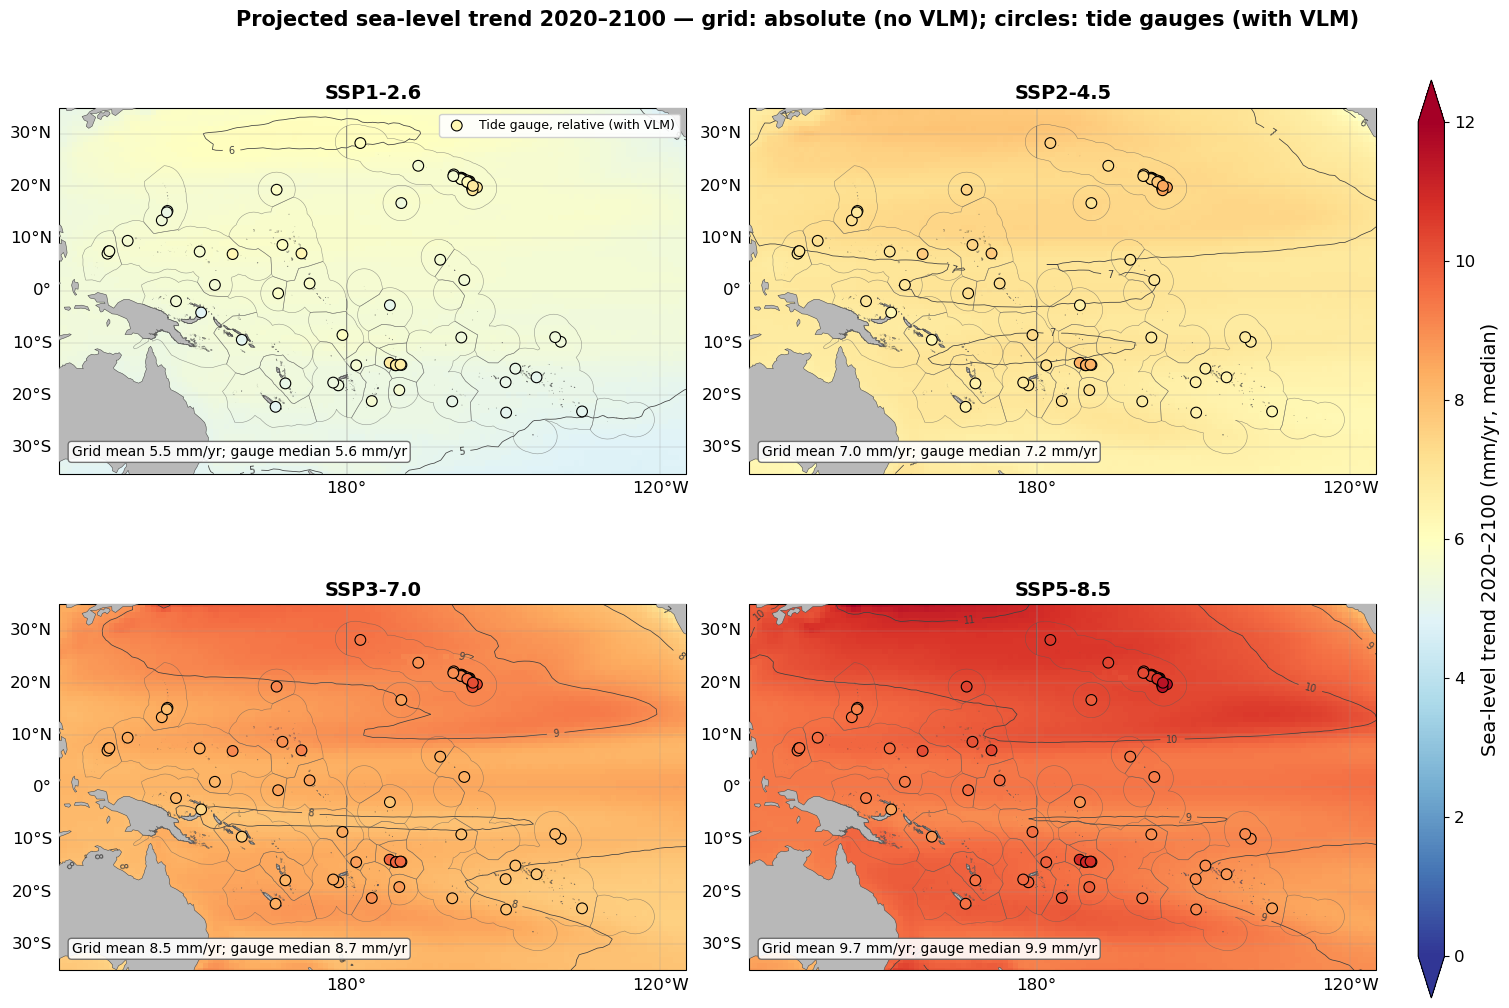

In [6]:
trend_mm = 10 * linear_trend(change.sel(quantile=0.5), *trend_period)
station_trend = 10 * linear_trend(station_change.sel(scenario=ssp_scenarios, quantile=0.5), *trend_period)
t_lo, t_hi = trend_scale(trend_mm, station_trend)
label = f'{trend_period[0]}–{trend_period[1]}'
fig = plot_projection_grid(
    {ssp_label(s): trend_mm.sel(scenario=s) for s in ssp_scenarios}, pacific,
    f'Projected sea-level trend {label} — grid: absolute (no VLM); circles: tide gauges (with VLM)',
    f'Sea-level trend {label} (mm/yr, median)', cmap=TREND_CMAP, vmin=t_lo, vmax=t_hi, contour_levels=colour_limits(trend_mm, 1)[2],
    gauges=stations, gauge_values={ssp_label(s): station_trend.sel(scenario=s).values for s in ssp_scenarios},
    annotations={ssp_label(s): f"Grid mean {float(domain_mean(trend_mm.sel(scenario=s))):.1f} mm/yr; "
                               f"gauge median {np.nanmedian(station_trend.sel(scenario=s).values):.1f} mm/yr" for s in ssp_scenarios},
    filename=fig_dir / f'PRJ_SL_trend_{trend_period[0]}_{trend_period[1]}_grid_and_stations_pacific.png',
)
plt.show()

## 5. Stations versus the surrounding grid

Relative change at each tide gauge minus the absolute change of the grid at the same AR6 location (no-VLM product), by 2100, for every scenario. It quantifies what the maps show visually: values far from zero mark gauges where vertical land motion dominates the local difference. Stations are ordered by the mean difference across scenarios.

In [7]:
year = horizons[-1]
rows = []
for i, st in stations.iterrows():
    loc = int(st['ar6_location'])
    row = {'station': f"{st['name']} ({st['eez']})", 'ar6_kind': st['ar6_kind']}
    for scenario in ssp_scenarios:
        rel = float(station_change.sel(scenario=scenario, quantile=0.5, year=year).isel(station=i))
        if st['ar6_kind'] == 'tide gauge' and loc in sl.gauge.values:
            absolute = float(sl['gauge_change'].sel(scenario=scenario, quantile=0.5, year=year, gauge=loc))
        elif st['ar6_kind'] == 'grid cell':
            absolute = float(change.sel(scenario=scenario, quantile=0.5, year=year,
                                        lat=float(locs.lat.sel(location=loc)), lon=float(locs.lon.sel(location=loc))))
        else:
            absolute = np.nan
        row[f'{ssp_label(scenario)} relative (cm)'] = round(rel, 1)
        row[f'{ssp_label(scenario)} absolute (cm)'] = round(absolute, 1)
        row[f'{ssp_label(scenario)} difference (cm)'] = round(rel - absolute, 1)
    rows.append(row)
comparison = pd.DataFrame(rows)
diff_cols = [c for c in comparison.columns if c.endswith('difference (cm)')]
comparison = comparison.assign(_order=comparison[diff_cols].mean(axis=1)).sort_values('_order', ascending=False).drop(columns='_order')
comparison.to_csv(tab_dir / f'PRJ_SL_stations_vs_grid_{year}_pacific.csv', index=False)
comparison[['station', 'ar6_kind'] + diff_cols]

,station,ar6_kind,SSP1-2.6 difference (cm),SSP2-4.5 difference (cm),SSP3-7.0 difference (cm),SSP5-8.5 difference (cm)
31,Pago Pago (American Samoa),tide gauge,13.8,13.8,13.8,13.8
41,Aunuu (American Samoa),tide gauge,13.8,13.8,13.8,13.8
40,Auasi (American Samoa),tide gauge,13.8,13.8,13.8,13.8
38,Apia (Samoa),tide gauge,13.4,13.3,13.4,13.4
43,Ofu (American Samoa),grid cell,12.7,12.6,12.6,12.6
...,...,...,...,...,...,...
68,Tinian (Northern Mariana Islands and Guam),grid cell,-3.6,-3.7,-3.7,-3.8
19,Saipan (Northern Mariana Islands and Guam),tide gauge,-3.7,-3.8,-3.8,-3.8
9,Kanton (Phoenix Group),tide gauge,-4.4,-4.2,-4.2,-4.3
6,Honiara (Solomon Islands),tide gauge,-5.0,-4.9,-5.0,-4.8


## Interpretation and reproducibility notes

- **Two products on one map:** the background is `ar6-regional_novlm-confidence` (absolute sea level, comparable with altimetry); the circles are `ar6-regional-confidence` (relative sea level, including vertical land motion, comparable with tide gauges). Both are IPCC AR6 medium-confidence medians relative to 1995–2014 (Garner et al., 2021, Zenodo [10.5281/zenodo.6382554](https://doi.org/10.5281/zenodo.6382554)).
- **Reading the circles:** a circle darker than its surroundings means more local rise than the ocean around it (subsidence, e.g. American Samoa and Samoa after the 2009 earthquake, or Hawaii); a lighter circle means uplift. AR6 extrapolates observed land-motion rates linearly, which is uncertain where motion is episodic.
- **Matching:** gauges without an AR6 tide-gauge location within 30 km use the nearest grid cell of the VLM product, whose land-motion term is generic; for those the difference with the background is small by construction.
- **Colour scale:** sequential, from the minimum to the maximum of grid and station values together; contours refer to the grid only.
- For uncertainty ranges, regional means and EEZ tables see [the regional maps](regional_indicators.ipynb) and [the station projections](station_projections.ipynb).